# Spoken Grammar Scoring Engine
**SHL Hiring Assessment 2026** - VEER AMOL SINGH ( veer.amol636@gmail.com | veer23588@iiitd.ac.in )
[first submission of the competition]
| | |
|---|---|
| **Training RMSE** (final models predicting the training clips they were fitted on) | **0.1124** (Pearson 0.9959) |
| **5-fold cross-validated RMSE** (honest estimate on unseen clips) | **0.4919** (Pearson 0.9180) |
| Baseline: always predict the mean score | 1.2382 |
| **Public leaderboard score** (~60 % of test) | **0.3540** (rank 2 when submitted) |

## Approach
Grammar is judged from what a person says, also how fluently they say it.

1. Transcript - Whisper transcribes the clip (keeping hesitations and errors), then grammar-specific models
   measure it: a grammar-error-correction model (how many edits does each sentence need), a grammatical-acceptability
   classifier (CoLA), a language model (how surprising is the word order?) and a DeBERTa model fine-tuned to predict the score.
2. Audio view- WavLM-Large speech embeddings (capture fluency, rhythm and accent) plus hand-crafted
   pause / speaking-rate / pitch features.
3. Ensemble - LightGBM, Ridge and SVR models on those features, out-of-fold predictions combined by a
   non-negative linear stacker, clipped to [0, 5].

## Pipeline
```
                        +--> Whisper large-v3-turbo --> transcript + word timings + language-ID
   audio.wav (16 kHz) --+                                   |
                        |                                   +--> speech statistics (rate, pauses, fillers, vocabulary)
                        |                                   +--> CoLA RoBERTa : sentence acceptability (+ 768-d embedding)
                        |                                   +--> CoEdIT : grammar-error correction -> edits per 100 words
                        |                                   +--> Qwen2.5-0.5B : language-model surprisal
                        |                                   +--> DeBERTa-v3-base fine-tuned on the score (5-fold)
                        |
                        +--> WavLM-Large : mean-pooled hidden states (best layers) + prosody features
                                                            |
                    LightGBM | Ridge | SVR base models (same 5 folds)  --> out-of-fold predictions
                                                            |
                              non-negative linear stacker --> clip to [0, 5] --> submission.csv
```


Note: transcription, WavLM, the grammar models and DeBERTa need a GPU and take about 2 hours, so their results are saved in features/ and loaded here. Their full code is shown in the notebook. Set RUN_HEAVY = True in the setup cell to recompute them.

## 0. Setup

In [1]:
import json, os, platform, re, sys, time, warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import soundfile as sf
import torch
import torch.nn as nn
import torch.nn.functional as F
from IPython.display import display
from lightgbm import LGBMRegressor
from scipy.stats import pearsonr
from sklearn.base import clone
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")
os.environ["TOKENIZERS_PARALLELISM"] = "false"

# ----- switches ---------------------------------------------------------------------------------------------
RUN_HEAVY = False   # True = recompute transcripts / WavLM / grammar models / DeBERTa from the raw audio (GPU, ~2 h)

# ----- paths & constants ------------------------------------------------------------------------------------
ROOT = Path.cwd()                       # run the notebook from the project folder
DATA_DIR = ROOT / "data" / "Dataset_Final"
FEAT_DIR = ROOT / "features"            # cached intermediate results
OUT_DIR = ROOT / "outputs"
FEAT_DIR.mkdir(exist_ok=True); OUT_DIR.mkdir(exist_ok=True)
META_CSV = FEAT_DIR / "meta.csv"
TRANSCRIPTS = FEAT_DIR / "transcripts.jsonl"
SR, SEED, N_FOLDS = 16_000, 42, 5
assert (DATA_DIR / "train.csv").exists(), "run this notebook from the project folder (data/Dataset_Final must exist)"

# ----- plotting style: fixed-order categorical colours, thin marks, recessive grid --------------------------
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e5e4e0"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.7, "axes.axisbelow": True,
    "legend.frameon": False, "font.size": 10,
})
print(f"python {platform.python_version()} | torch {torch.__version__} | cuda available: {torch.cuda.is_available()}")

python 3.13.7 | torch 2.11.0+cu128 | cuda available: True


### helpers


In [2]:
# ----- helpers copied verbatim from src/common.py --------------------------------------------------------
def load_meta() -> pd.DataFrame:
    """One row per audio file: key, split, filename, label (NaN for test), duration, fold (-1 for test).

    Train and test folders reuse the same file names, so `key` = "<split>/<filename>" is the
    unique id used by every feature table.
    """
    if not META_CSV.exists():
        raise SystemExit("features/meta.csv not found - run src/01_prepare_data.py first.")
    return pd.read_csv(META_CSV)

def audio_path(split: str, filename: str) -> Path:
    return DATA_DIR / split / filename

def load_audio(path) -> np.ndarray:
    """Mono float32 waveform at 16 kHz."""
    import soundfile as sf

    wav, sr = sf.read(str(path), dtype="float32", always_2d=True)
    wav = wav.mean(axis=1)
    if sr != SR:
        import librosa

        wav = librosa.resample(wav, orig_sr=sr, target_sr=SR)
    return np.ascontiguousarray(wav, dtype=np.float32)

def load_transcripts(missing_ok: bool = False) -> dict[str, dict]:
    """Whisper output of step 2, keyed by `key`."""
    if not TRANSCRIPTS.exists():
        if missing_ok:
            return {}
        raise SystemExit("features/transcripts.jsonl not found - run src/02_transcribe.py first.")
    records = {}
    with open(TRANSCRIPTS, encoding="utf-8") as f:
        for line in f:
            if line.strip():
                rec = json.loads(line)
                records[rec["key"]] = rec
    return records

def get_device():
    import torch

    return torch.device("cuda" if torch.cuda.is_available() else "cpu")

def expose_cuda_dlls() -> None:
    """Windows only: let CTranslate2 (faster-whisper) find the cuBLAS / cuDNN DLLs bundled with PyTorch."""
    if os.name != "nt":
        return
    import site

    import torch  # noqa: F401  (importing torch also loads its CUDA DLLs into the process)

    candidates = [Path(torch.__file__).parent / "lib"]
    for sp in site.getsitepackages():
        candidates += [Path(sp) / "nvidia" / pkg / "bin" for pkg in ("cublas", "cudnn", "cuda_runtime")]
    for d in candidates:
        if d.is_dir():
            os.add_dll_directory(str(d))
            os.environ["PATH"] = str(d) + os.pathsep + os.environ.get("PATH", "")

FILLERS = {"um", "umm", "uh", "uhh", "uhm", "er", "erm", "ah", "ahh", "hmm", "hm", "mm", "mmm", "mhm", "eh"}

_FILLER_RE = re.compile(r",?\s*\b(?:" + "|".join(sorted(FILLERS, key=len, reverse=True)) + r")\b[,.!?]*", re.I)

_WORD_RE = re.compile(r"[a-z0-9]+(?:'[a-z]+)?")

def words_of(text: str) -> list[str]:
    """Lower-cased word tokens without punctuation (keeps contractions like don't)."""
    return _WORD_RE.findall(text.lower())

def strip_fillers(text: str) -> str:
    """Remove um/uh-style fillers: they are a fluency signal, not a grammar error."""
    text = _FILLER_RE.sub(" ", text)
    text = re.sub(r"\s+([,.!?])", r"\1", text)
    text = re.sub(r"(^|[.!?]\s+)[,\s]+", r"\1", text)
    return re.sub(r"\s{2,}", " ", text).strip()

def split_sentences(text: str, max_words: int = 40) -> list[str]:
    """Split on Whisper's sentence punctuation; very long run-ons are cut into max_words chunks."""
    out = []
    for part in re.split(r"(?<=[.!?])\s+", text.strip()):
        tokens = part.split()
        for i in range(0, len(tokens), max_words):
            out.append(" ".join(tokens[i : i + max_words]))
    return [s for s in out if s]

def word_edit_distance(a: list[str], b: list[str]) -> int:
    """Levenshtein distance between two word sequences (insertions, deletions, substitutions)."""
    prev = list(range(len(b) + 1))
    for i, wa in enumerate(a, 1):
        cur = [i]
        for j, wb in enumerate(b, 1):
            cur.append(min(prev[j] + 1, cur[j - 1] + 1, prev[j - 1] + (wa != wb)))
        prev = cur
    return prev[-1]

### Evaluation utilities

* RMSE is the main metric, and Pearson correlation is the second one used by the leaderboard.
* We use 5-fold cross-validation.

In [3]:
# ----- evaluation utilities (from src/06_train_ensemble.py) ---------------------------------------------------
ALPHAS = np.logspace(-1, 5, 25)

LENGTH_DEPENDENT = ["n_words", "n_sentences", "gec_max_edits"]

def rmse(a, b):
    return float(np.sqrt(np.mean((np.asarray(a) - np.asarray(b)) ** 2)))

def pearson(a, b):
    return float(pearsonr(a, b)[0])

def ridge():
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), RidgeCV(alphas=ALPHAS))

def svr(c):
    return make_pipeline(StandardScaler(), SVR(C=c, epsilon=0.1))

def lgbm():
    return LGBMRegressor(n_estimators=500, learning_rate=0.02, num_leaves=15, min_child_samples=15,
                         subsample=0.8, subsample_freq=1, colsample_bytree=0.6, reg_lambda=1.0,
                         random_state=SEED, verbose=-1)

class CV:
    """Runs every model on the same folds; keeps OOF, test and in-sample predictions."""

    def __init__(self, y, folds):
        self.y, self.folds = y, folds

    def oof(self, model, X):
        pred = np.zeros(len(self.y))
        for f in range(N_FOLDS):
            m = clone(model).fit(X[self.folds != f], self.y[self.folds != f])
            pred[self.folds == f] = m.predict(X[self.folds == f])
        return pred

    def run(self, model, X_tr, X_te):
        """-> (OOF predictions, test predictions = mean of fold models, in-sample predictions of a full fit)."""
        oof, test = np.zeros(len(self.y)), np.zeros(len(X_te))
        for f in range(N_FOLDS):
            m = clone(model).fit(X_tr[self.folds != f], self.y[self.folds != f])
            oof[self.folds == f] = m.predict(X_tr[self.folds == f])
            test += m.predict(X_te) / N_FOLDS
        full = clone(model).fit(X_tr, self.y)
        return oof, test, full.predict(X_tr), full

def pick_svr_c(cv, X, grid=(1, 3, 10)):
    scores = {c: rmse(cv.oof(svr(c), X), cv.y) for c in grid}
    return min(scores, key=scores.get)

## 1. Data understanding
The dataset has 769 labelled training clips and 216 test clips (WAV, 16 kHz mono). Labels are MOS grammar scores
(0-5, in steps of 0.5). I build one metadata table for both splits and 5 stratified folds for cross-validation.

In [4]:
train = pd.read_csv(DATA_DIR / "train.csv").assign(split="train")
test = pd.read_csv(DATA_DIR / "test.csv").assign(split="test", label=np.nan)   # test labels in the csv are dummies
meta = pd.concat([train, test], ignore_index=True)
# train/ and test/ reuse file names (audio_12.wav exists in both), so the unique id is "<split>/<filename>"
meta["key"] = meta["split"] + "/" + meta["filename"]
meta["duration"] = [round(sf.info(str(DATA_DIR / s / f)).duration, 2) for s, f in zip(meta["split"], meta["filename"])]

# 5 stratified folds on binned labels: 0 | 1-2 | 2.5-3 | 3.5-4 | 4.5-5
bins = np.digitize(train["label"], [0.5, 2.25, 3.25, 4.25])
folds = np.full(len(meta), -1)                                           # -1 = test rows
for f, (_, val_idx) in enumerate(StratifiedKFold(N_FOLDS, shuffle=True, random_state=SEED).split(np.zeros(len(train)), bins)):
    folds[val_idx] = f
meta["fold"] = folds
meta = meta[["key", "split", "filename", "label", "duration", "fold"]]

# the cached features were built with exactly these folds
assert pd.read_csv(META_CSV)[["key", "fold"]].equals(meta[["key", "fold"]])
tr_meta = meta[meta.split == "train"]
print(f"train {len(tr_meta)} clips | test {(meta.split == 'test').sum()} clips")
print(f"label mean {tr_meta.label.mean():.3f}, std {tr_meta.label.std():.3f}  -> predicting the mean gives RMSE {np.sqrt(np.mean((tr_meta.label - tr_meta.label.mean())**2)):.3f}")

train 769 clips | test 216 clips
label mean 3.313, std 1.239  -> predicting the mean gives RMSE 1.238


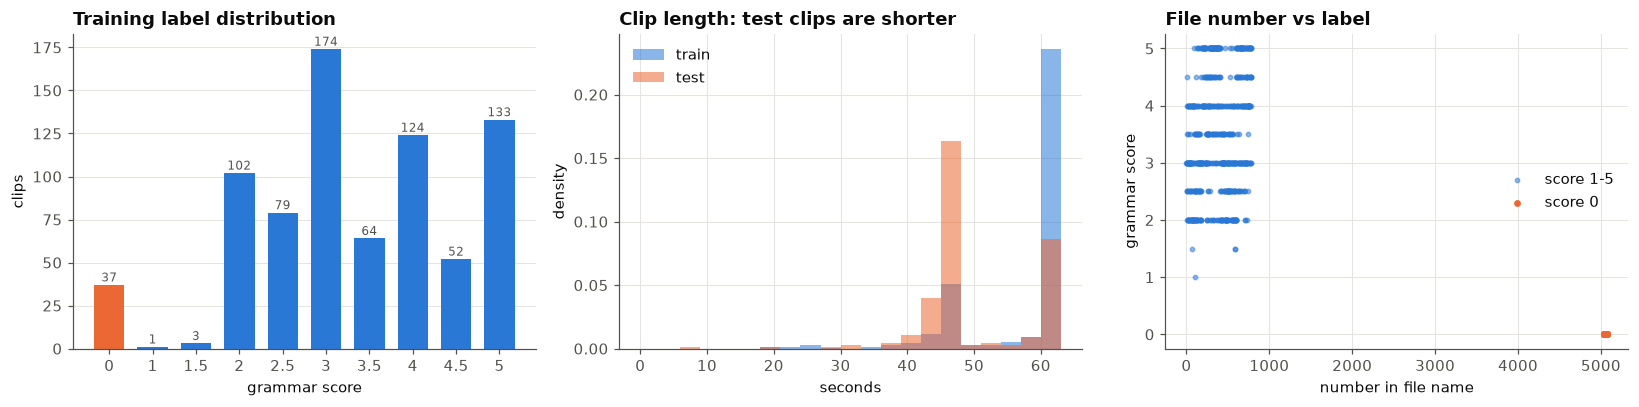

score-0 clips: 37, file numbers 5037-5073 (all consecutive: True)
median clip length  train 60.1s | test 45.1s
correlation(file number, label) in train: -0.55


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))

# (a) label distribution
counts = tr_meta["label"].value_counts().sort_index()
bars = axes[0].bar([f"{v:g}" for v in counts.index], counts.values, color=[ORANGE if v == 0 else BLUE for v in counts.index], width=0.7)
for b, c in zip(bars, counts.values):
    axes[0].text(b.get_x() + b.get_width() / 2, c + 2, str(c), ha="center", fontsize=8, color=MUTED)
axes[0].set(title="Training label distribution", xlabel="grammar score", ylabel="clips")
axes[0].grid(axis="x", visible=False)

# (b) clip length: train vs test
edges = np.arange(0, 66, 3)
axes[1].hist(tr_meta["duration"], bins=edges, density=True, color=BLUE, alpha=0.55, label="train")
axes[1].hist(meta[meta.split == "test"]["duration"], bins=edges, density=True, color=ORANGE, alpha=0.55, label="test")
axes[1].set(title="Clip length: test clips are shorter", xlabel="seconds", ylabel="density"); axes[1].legend()

# (c) file number vs label: the score-0 clips are one consecutive batch
idx = tr_meta["filename"].str.extract(r"(\d+)")[0].astype(int)
zero = tr_meta["label"] == 0
axes[2].scatter(idx[~zero], tr_meta["label"][~zero], s=8, color=BLUE, alpha=0.5, label="score 1-5")
axes[2].scatter(idx[zero], tr_meta["label"][zero], s=12, color=ORANGE, label="score 0")
axes[2].set(title="File number vs label", xlabel="number in file name", ylabel="grammar score"); axes[2].legend(loc="center right")
plt.tight_layout(); plt.show()

print(f"score-0 clips: {zero.sum()}, file numbers {idx[zero].min()}-{idx[zero].max()} (all consecutive: {np.all(np.diff(np.sort(idx[zero])) == 1)})")
print(f"median clip length  train {tr_meta.duration.median():.1f}s | test {meta[meta.split=='test'].duration.median():.1f}s")
print(f"correlation(file number, label) in train: {np.corrcoef(idx, tr_meta['label'])[0, 1]:.2f}")

What the data shows:
* 37 clips are labelled 0, even though the rubric runs from 1 to 5. They have consecutive file numbers (5037 to 5073), so they are a separate batch. We keep them and test dropping them in section 5.
* Test clips are shorter than train clips (median 45 s against 60 s), so we only use per-minute and per-word features, not raw totals like word count.
* Train and test reuse file names, so every clip is identified by its split plus its file name.
* In train, the file number correlates with the label (r = -0.55). That is a leak, so file names are never used as a feature.

## 2. Preprocessing: speech-to-text with Whisper
Grammar can't be measured from raw audio, so we first convert each clip to text with Whisper. We give it a short prompt containing "umm" and false starts, so it keeps the speaker's mistakes instead of quietly fixing them.

In [6]:
# ----- code that produced features/transcripts.jsonl (from src/02_transcribe.py) -------------------------------
PROMPT = "Umm, let me think like, hmm... Okay, here's what I'm, like, thinking. So, uh, I- I was going there."

def language_probs(model, audio):
    """Whisper language ID on the first 30 s -> (P(English), top language, P(top language))."""
    try:
        _, _, probs = model.detect_language(audio)
    except (AttributeError, TypeError):  # older faster-whisper: detection happens inside transcribe()
        _, info = model.transcribe(audio[: 30 * SR], language=None)
        probs = info.all_language_probs or []
    probs = dict(probs)
    top = max(probs, key=probs.get) if probs else "en"
    return float(probs.get("en", 0.0)), top, float(probs.get(top, 0.0))

def transcribe_one(model, audio, beam_size):
    en_prob, top_lang, top_prob = language_probs(model, audio)
    segments, info = model.transcribe(
        audio,
        language="en",                     # force English: accented English is often mis-detected
        beam_size=beam_size,
        word_timestamps=True,              # needed for pause / speech-rate features
        condition_on_previous_text=False,  # prevents repetition loops across segments
        initial_prompt=PROMPT,
        vad_filter=True,                   # skip silence -> no hallucinated text on silent clips
    )
    segs, words = [], []
    for s in segments:
        segs.append({
            "start": round(s.start, 2), "end": round(s.end, 2), "text": s.text.strip(),
            "avg_logprob": round(s.avg_logprob, 4), "no_speech_prob": round(s.no_speech_prob, 4),
            "compression_ratio": round(s.compression_ratio, 4),
        })
        words += [{"w": w.word.strip(), "s": round(w.start, 2), "e": round(w.end, 2), "p": round(w.probability, 4)}
                  for w in (s.words or [])]
    return {
        "text": " ".join(s["text"] for s in segs).strip(),
        "duration": round(len(audio) / SR, 2),
        "speech_duration": round(float(getattr(info, "duration_after_vad", 0.0) or 0.0), 2),
        "en_prob": round(en_prob, 4), "top_lang": top_lang, "top_lang_prob": round(top_prob, 4),
        "segments": segs, "words": words,
    }


def run_transcription(model_name="large-v3-turbo", beam=5):
    """Transcribe every clip that is not in transcripts.jsonl yet (resumable)."""
    expose_cuda_dlls()
    from faster_whisper import WhisperModel
    model = WhisperModel(model_name, device="cuda", compute_type="int8_float16")
    done = set(load_transcripts(missing_ok=True))
    todo = meta[~meta["key"].isin(done)]
    with open(TRANSCRIPTS, "a", encoding="utf-8") as fout:
        for row in tqdm(todo.itertuples(), total=len(todo), desc="transcribing"):
            rec = transcribe_one(model, load_audio(audio_path(row.split, row.filename)), beam)
            fout.write(json.dumps({"key": row.key, **rec}) + "\n")
            fout.flush()


if RUN_HEAVY:
    run_transcription()
transcripts = load_transcripts()
assert set(meta["key"]) == set(transcripts), "transcripts missing - set RUN_HEAVY = True"
print(f"{len(transcripts)} transcripts loaded")

985 transcripts loaded


In [7]:
pd.set_option("display.max_colwidth", 230)
rows = []
for v in [5.0, 4.0, 3.0, 2.0, 0.0]:
    k = tr_meta[tr_meta.label == v].sample(1, random_state=3)["key"].iloc[0]
    rows.append({"clip": k, "score": v, "words": len(transcripts[k]["text"].split()), "text (first 230 chars)": transcripts[k]["text"][:230]})
display(pd.DataFrame(rows))

tw = meta["key"].map(lambda k: len(transcripts[k]["text"].split()))
lp = meta["key"].map(lambda k: np.mean([s["avg_logprob"] for s in transcripts[k]["segments"]] or [np.nan]))
print(f"words per clip: median {tw.median():.0f}, min {tw.min()}, max {tw.max()}   |   clips with <20 words: {(tw < 20).sum()}")
en = meta["key"].map(lambda k: transcripts[k]["en_prob"])
low_en = meta[en < 0.5]
print(f"clips with Whisper P(English) < 0.5: train {(low_en.split == 'train').sum()} (labels {low_en.label.tolist()}), test {(low_en.split == 'test').sum()}")
print("  -> heavily accented / unclear speech, not another language: their transcripts are English. Half of them belong to the score-0 batch.")

,clip,score,words,text (first 230 chars)
0,train/audio_688.wav,5.0,70,"The playground looks like an average school playground with some basketball hoops, some slides, some swings, and a sandbox in the middle. Um, I can see that some of the popular activities are playing basketball and playing tag..."
1,train/audio_579.wav,4.0,100,"In the heart of this school year, the playground scrolls like a vibrant canvas, teeming with life and energy. Children of all ages just fill the space, each adding their own breaststroke to the masterpiece of play. Underneath ..."
2,train/audio_10.wav,3.0,76,"Well, at the time I reached the resort, I go to my room, I relax for a bit, then I change clothes and go to the pool, relax, take any tour is available on the locations, and also party. I like to party, I like to meet people a..."
3,train/audio_177.wav,2.0,113,"My school playground is very big. It's very huge. There are trees at the boundaries. All the trees cover the edges of the playground. And there were children's, approximately 30 to 40, who play daily in the playground. I heard..."
4,train/audio_5039.wav,0.0,39,"Umm, the school playground is a lovely hub for activities where children come to the land, and because I can unleash their activity. The playgrounds, which of them, are joined with, um, colorful equipment, tinted lines, for ga..."


words per clip: median 103, min 8, max 178   |   clips with <20 words: 1
clips with Whisper P(English) < 0.5: train 6 (labels [0.0, 0.0, 2.5, 0.0, 3.0, 2.5]), test 0
  -> heavily accented / unclear speech, not another language: their transcripts are English. Half of them belong to the score-0 batch.


The transcripts keep the speakers' mistakes ("these trees **gives** a very greenery view", "having a more, more greenery trees") and
hesitations ("there are, there are", "um"), which is what the grammar models need.
Sanity checks on the transcripts: no looping / hallucinated output (compression ratio), and transcripts end
within the audio - the 25 clips whose transcript stops early really do fall silent (checked against the waveform).

## 3. Feature engineering
### 3.1 Audio features
We use WavLM, a pre-trained speech model, to turn each clip's audio into a set of numbers (an embedding) that captures how the person speaks, such as fluency and rhythm. We also add a few simple features like pause length and pitch variation. These matter because people who speak fluently tend to have better grammar.

In [8]:
# ----- code that produced features/wavlm_layers.npy and acoustic.csv (from src/03_audio_features.py) ------------
import librosa
from transformers import WavLMModel

WAVLM_MODEL = "microsoft/wavlm-large"

CHUNK_S = 30          # WavLM is run on <=30 s chunks to bound GPU memory

HOP = 160             # 10 ms analysis hop for prosody

PAUSE_MIN_FRAMES = 30   # a silence >= 0.3 s counts as a pause

LONG_PAUSE_FRAMES = 100  # >= 1 s is a long pause

@torch.inference_mode()
def wavlm_layer_means(model, wav, device, use_amp=True):
    """Time-averaged hidden state of every WavLM layer -> (n_layers + 1, hidden)."""
    n_chunks = max(1, int(np.ceil(len(wav) / (CHUNK_S * SR))))
    sums, frames = None, 0
    for chunk in np.array_split(wav, n_chunks):
        x = (chunk - chunk.mean()) / (chunk.std() + 1e-7)  # WavLM-Large was trained on normalised audio
        x = torch.from_numpy(np.ascontiguousarray(x)).float().unsqueeze(0).to(device)
        amp = (torch.autocast("cuda", dtype=torch.float16) if use_amp and device.type == "cuda"
               else contextlib.nullcontext())
        with amp:
            hidden = model(x, output_hidden_states=True).hidden_states
        h = torch.stack(hidden, 0)[:, 0].float()  # (layers, T, hidden)
        sums = h.sum(1) if sums is None else sums + h.sum(1)
        frames += h.shape[1]
    out = (sums / frames).cpu().numpy()
    if use_amp and not np.isfinite(out).all():  # fp16 overflow -> redo this clip in fp32
        return wavlm_layer_means(model, wav, device, use_amp=False)
    return out

def run_lengths(mask):
    """Lengths of consecutive True runs in a boolean array."""
    padded = np.concatenate([[0], mask.astype(np.int8), [0]])
    d = np.diff(padded)
    return np.where(d == -1)[0] - np.where(d == 1)[0]

def acoustic_features(wav):
    rms = librosa.feature.rms(y=wav, frame_length=400, hop_length=HOP)[0]
    db = 20 * np.log10(rms + 1e-6)
    active = db > np.percentile(db, 95) - 35  # frames within 35 dB of the loud part = speech
    if active.sum() < 10:
        return {"ac_active_ratio": float(active.mean())}

    first, last = np.flatnonzero(active)[[0, -1]]
    inner_silence = ~active[first : last + 1]  # ignore leading / trailing silence
    pauses = run_lengths(inner_silence)
    pauses = pauses[pauses >= PAUSE_MIN_FRAMES]
    span_min = (last - first + 1) * HOP / SR / 60

    f0 = librosa.yin(wav, fmin=70, fmax=400, sr=SR, frame_length=1024, hop_length=HOP)
    n = min(len(f0), len(active))
    f0 = f0[:n][active[:n]]
    semitones = 12 * np.log2(f0 / np.median(f0))

    return {
        "ac_active_ratio": float(active.mean()),
        "ac_pauses_per_min": len(pauses) / span_min,
        "ac_long_pauses_per_min": float((pauses >= LONG_PAUSE_FRAMES).sum()) / span_min,
        "ac_mean_pause_s": float(pauses.mean() * HOP / SR) if len(pauses) else 0.0,
        "ac_loudness_mean": float(db[active].mean()),
        "ac_loudness_std": float(db[active].std()),
        "ac_f0_median": float(np.median(f0)),
        "ac_pitch_std_st": float(semitones.std()),
        "ac_pitch_range_st": float(np.percentile(semitones, 95) - np.percentile(semitones, 5)),
    }


def run_audio_features():
    device = get_device()
    model = WavLMModel.from_pretrained(WAVLM_MODEL).to(device).eval()
    emb = np.zeros((len(meta), model.config.num_hidden_layers + 1, model.config.hidden_size), dtype=np.float16)
    rows = []
    for i, row in enumerate(tqdm(meta.itertuples(), total=len(meta), desc="audio features")):
        wav = load_audio(audio_path(row.split, row.filename))
        emb[i] = wavlm_layer_means(model, wav, device)
        rows.append({"key": row.key, **acoustic_features(wav)})
    np.save(FEAT_DIR / "wavlm_layers.npy", emb)
    pd.DataFrame(rows).to_csv(FEAT_DIR / "acoustic.csv", index=False)


if RUN_HEAVY:
    run_audio_features()
wavlm = np.load(FEAT_DIR / "wavlm_layers.npy").astype(np.float32)
acoustic = pd.read_csv(FEAT_DIR / "acoustic.csv")
print("WavLM embeddings:", wavlm.shape, "(clips, layers, dims) | prosody features:", acoustic.shape[1] - 1)

WavLM embeddings: (985, 25, 1024) (clips, layers, dims) | prosody features: 9


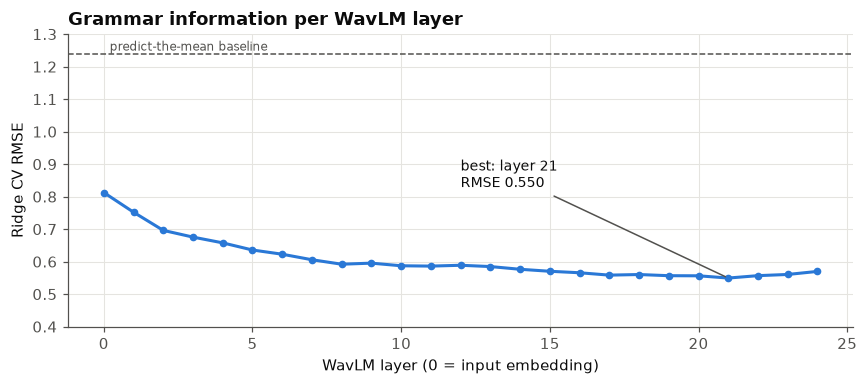

In [9]:
# Which WavLM layer predicts the grammar score best? Ridge regression on one layer at a time, 5-fold CV.
is_tr_all = (meta["split"] == "train").to_numpy()
y_all, folds_all = meta.loc[is_tr_all, "label"].to_numpy(), meta.loc[is_tr_all, "fold"].to_numpy()
cv_all = CV(y_all, folds_all)
layer_rmse_all = [rmse(cv_all.oof(ridge(), wavlm[is_tr_all, L]), y_all) for L in range(wavlm.shape[1])]

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(range(len(layer_rmse_all)), layer_rmse_all, color=BLUE, lw=2, marker="o", ms=4)
best = int(np.argmin(layer_rmse_all))
ax.axhline(1.238, color=MUTED, ls="--", lw=1); ax.text(0.2, 1.24, "predict-the-mean baseline", color=MUTED, fontsize=8, va="bottom")
ax.annotate(f"best: layer {best}\nRMSE {layer_rmse_all[best]:.3f}", (best, layer_rmse_all[best]), xytext=(best - 9, layer_rmse_all[best] + 0.28),
            arrowprops=dict(arrowstyle="-", color=MUTED), color=INK, fontsize=9)
ax.set(title="Grammar information per WavLM layer", xlabel="WavLM layer (0 = input embedding)", ylabel="Ridge CV RMSE", ylim=(0.4, 1.3))
plt.tight_layout(); plt.show()

Even the audio alone (no transcript) reaches an RMSE of about 0.55 - well below the 1.24 baseline - and the curve
peaks in the upper-middle layers (around 19-22), as expected. The ensemble uses the best layer and its two neighbours, averaged.

### 3.2 Transcript features


<table>
<tr><td>Family</td><td>Model / method</td></tr>
<tr><td>Speech statistics</td><td>plain Python on Whisper output</td></tr>
<tr><td>CoLA acceptability</td><td>RoBERTa fine-tuned on CoLA</td></tr>
<tr><td>Grammar error correction</td><td>Grammarly CoEdIT-large</td></tr>
<tr><td>Language-model surprisal</td><td>Qwen2.5-0.5B</td></tr>
</table>


In [10]:
# ----- speech statistics (live) - from src/04_text_features.py -----------------------------------------------
try:
    from wordfreq import zipf_frequency
except ImportError:  # optional dependency
    zipf_frequency = None

SUBORDINATORS = {"because", "although", "though", "which", "who", "whom", "whose", "when", "whenever", "while",
                 "whereas", "if", "unless", "since", "until", "after", "before", "that", "where", "whether"}

TIMING_KEYS = ["speak_span_ratio", "wpm_span", "artic_rate", "pauses_03_per_min", "pauses_1_per_min",
               "mean_pause", "max_pause", "word_prob_mean", "word_prob_p10", "low_prob_frac"]

def timing_stats(words, duration):
    """Speech-rate and pause features from Whisper word timestamps and word confidences."""
    if len(words) < 2:
        return dict.fromkeys(TIMING_KEYS, np.nan)
    start = np.array([w["s"] for w in words])
    end = np.array([w["e"] for w in words])
    prob = np.array([w["p"] for w in words])
    span = max(end[-1] - start[0], 1e-3)
    gaps = np.clip(start[1:] - end[:-1], 0, None)
    phonation = max(np.clip(end - start, 0, None).sum(), 1e-3)
    return {
        "speak_span_ratio": span / duration,
        "wpm_span": len(words) / span * 60,
        "artic_rate": len(words) / phonation * 60,
        "pauses_03_per_min": (gaps > 0.3).sum() / span * 60,
        "pauses_1_per_min": (gaps > 1.0).sum() / span * 60,
        "mean_pause": gaps[gaps > 0.3].mean() if (gaps > 0.3).any() else 0.0,
        "max_pause": gaps.max(),
        "word_prob_mean": prob.mean(),
        "word_prob_p10": np.percentile(prob, 10),
        "low_prob_frac": (prob < 0.5).mean(),
    }

def transcript_stats(rec):
    duration = max(rec["duration"], 1e-3)
    tokens = words_of(rec["text"])
    content = [t for t in tokens if t not in FILLERS]
    n = len(content)
    f = {
        "en_prob": rec["en_prob"],
        "top_lang_prob": rec["top_lang_prob"],
        "is_english": float(rec["top_lang"] == "en"),
        "vad_speech_ratio": rec["speech_duration"] / duration,
        "n_words": n,
        "wpm": n / duration * 60,
        "filler_rate": (len(tokens) - n) / max(len(tokens), 1),
        "repeat_rate": sum(a == b for a, b in zip(content, content[1:])) / max(n, 1),
        "root_ttr": len(set(content)) / np.sqrt(n) if n else np.nan,  # length-robust vocabulary richness
        "mean_word_len": np.mean([len(t) for t in content]) if n else np.nan,
        "long_word_frac": np.mean([len(t) >= 7 for t in content]) if n else np.nan,
        "subord_per_100w": 100 * sum(t in SUBORDINATORS for t in content) / n if n else np.nan,
    }
    sent_lens = [len(words_of(s)) for s in split_sentences(strip_fillers(rec["text"]), max_words=10_000)]
    f["n_sentences"] = len(sent_lens)
    f["sent_len_mean"] = np.mean(sent_lens) if sent_lens else np.nan
    f["sent_len_std"] = np.std(sent_lens) if sent_lens else np.nan
    f["sent_len_max"] = max(sent_lens) if sent_lens else np.nan
    if zipf_frequency is not None:
        zipf = np.array([zipf_frequency(t, "en") for t in content])
        f["zipf_mean"] = zipf.mean() if n else np.nan
        f["rare_word_frac"] = (zipf < 3.5).mean() if n else np.nan

    segs = rec["segments"]
    f["seg_logprob_mean"] = np.mean([s["avg_logprob"] for s in segs]) if segs else np.nan
    f["seg_logprob_min"] = np.min([s["avg_logprob"] for s in segs]) if segs else np.nan
    f["no_speech_mean"] = np.mean([s["no_speech_prob"] for s in segs]) if segs else np.nan
    f["compression_mean"] = np.mean([s["compression_ratio"] for s in segs]) if segs else np.nan
    f.update(timing_stats(rec["words"], duration))
    return f

def stage_stats(keys, recs):
    return pd.DataFrame([{"key": k, **transcript_stats(r)} for k, r in zip(keys, recs)])

keys = meta["key"].tolist()
recs = [transcripts[k] for k in keys]
texts = [r["text"] for r in recs]
stats = stage_stats(keys, recs)

# reproducibility check against the cached table from the original run
cached_stats = pd.read_csv(FEAT_DIR / "text_stats.csv")
print("live statistics identical to cached:", np.allclose(stats.drop(columns="key").to_numpy(float), cached_stats.drop(columns="key").to_numpy(float), equal_nan=True, atol=1e-6))
print(f"{stats.shape[1] - 1} speech-statistic features, e.g. {list(stats.columns[1:8])}")

live statistics identical to cached: True
32 speech-statistic features, e.g. ['en_prob', 'top_lang_prob', 'is_english', 'vad_speech_ratio', 'n_words', 'wpm', 'filler_rate']


In [11]:
# ----- neural grammar features (heavy; cached) - from src/04_text_features.py ---------------------------------
from transformers import AutoModelForCausalLM, AutoModelForSeq2SeqLM, AutoModelForSequenceClassification, AutoTokenizer

COLA_MODEL = "textattack/roberta-base-CoLA"

GEC_MODEL = "grammarly/coedit-large"

GEC_PREFIX = "Fix grammatical errors in this sentence: "

LM_MODEL = "Qwen/Qwen2.5-0.5B"

@torch.inference_mode()
def acceptability(tok, model, sentences, device, batch_size=64):
    """P(label 1 = grammatically acceptable) for each sentence; length-sorted batches."""
    probs = np.zeros(len(sentences))
    order = np.argsort([len(s) for s in sentences])
    for i in tqdm(range(0, len(order), batch_size), desc="cola sentences"):
        idx = order[i : i + batch_size]
        enc = tok([sentences[j] for j in idx], padding=True, truncation=True, max_length=128,
                  return_tensors="pt").to(device)
        probs[idx] = model(**enc).logits.float().softmax(-1)[:, 1].cpu().numpy()
    return probs

@torch.inference_mode()
def mean_pooled_embeddings(tok, model, texts, device, batch_size=16):
    out = []
    for i in tqdm(range(0, len(texts), batch_size), desc="cola embeddings"):
        enc = tok(texts[i : i + batch_size], padding=True, truncation=True, max_length=512,
                  return_tensors="pt").to(device)
        h = model(**enc, output_hidden_states=True).hidden_states[-1]
        m = enc["attention_mask"].unsqueeze(-1).to(h.dtype)
        out.append(((h * m).sum(1) / m.sum(1).clamp(min=1)).float().cpu().numpy())
    return np.concatenate(out)

def stage_cola(keys, texts, device):
    tok = AutoTokenizer.from_pretrained(COLA_MODEL)
    model = AutoModelForSequenceClassification.from_pretrained(COLA_MODEL).to(device).eval()

    items = [(k, s) for k, t in zip(keys, texts) for s in split_sentences(strip_fillers(t))
             if len(s.split()) >= 3]
    df = pd.DataFrame(items, columns=["key", "sent"])
    df["p"] = acceptability(tok, model, df["sent"].tolist(), device) if len(df) else []
    df["nw"] = df["sent"].str.split().str.len()
    df["bad"] = (df["p"] < 0.5).astype(float)
    df["pw"] = df["p"] * df["nw"]
    agg = df.groupby("key").agg(cola_mean=("p", "mean"), cola_min=("p", "min"), cola_std=("p", "std"),
                                cola_bad_frac=("bad", "mean"), pw=("pw", "sum"), nw=("nw", "sum"))
    agg["cola_wmean"] = agg["pw"] / agg["nw"]
    feats = pd.DataFrame({"key": keys}).merge(agg.drop(columns=["pw", "nw"]), on="key", how="left")

    np.save(FEAT_DIR / "cola_emb.npy", mean_pooled_embeddings(tok, model, texts, device).astype(np.float32))
    return feats

@torch.inference_mode()
def correct(tok, model, sentences, device, batch_size=16):
    corrected = [""] * len(sentences)
    order = np.argsort([len(s) for s in sentences])
    for i in tqdm(range(0, len(order), batch_size), desc="grammar correction"):
        idx = order[i : i + batch_size]
        enc = tok([GEC_PREFIX + sentences[j] for j in idx], padding=True, truncation=True, max_length=192,
                  return_tensors="pt").to(device)
        out = model.generate(**enc, max_new_tokens=160, num_beams=1, do_sample=False)
        for j, text in zip(idx, tok.batch_decode(out, skip_special_tokens=True)):
            corrected[j] = text
    return corrected

def stage_gec(keys, texts, device):
    dtype = torch.bfloat16 if device.type == "cuda" and torch.cuda.is_bf16_supported() else torch.float32
    tok = AutoTokenizer.from_pretrained(GEC_MODEL)
    model = AutoModelForSeq2SeqLM.from_pretrained(GEC_MODEL).to(device=device, dtype=dtype).eval()

    items = [(k, s) for k, t in zip(keys, texts) for s in split_sentences(strip_fillers(t))
             if len(words_of(s)) >= 2]
    df = pd.DataFrame(items, columns=["key", "sent"])
    df["corrected"] = correct(tok, model, df["sent"].tolist(), device) if len(df) else []
    df["nw"] = [len(words_of(s)) for s in df["sent"]]
    df["edits"] = [word_edit_distance(words_of(a), words_of(b)) for a, b in zip(df["sent"], df["corrected"])]
    df["changed"] = (df["edits"] > 0).astype(float)
    df.to_csv(FEAT_DIR / "gec_corrections.csv", index=False)  # kept for inspection in the notebook

    agg = df.groupby("key").agg(edits=("edits", "sum"), nw=("nw", "sum"), gec_changed_frac=("changed", "mean"),
                                gec_max_edits=("edits", "max"), gec_mean_edits=("edits", "mean"))
    agg["gec_edits_per_100w"] = 100 * agg["edits"] / agg["nw"].clip(lower=1)
    return pd.DataFrame({"key": keys}).merge(agg.drop(columns=["edits", "nw"]), on="key", how="left")

@torch.inference_mode()
def stage_lm(keys, texts, device):
    dtype = torch.bfloat16 if device.type == "cuda" and torch.cuda.is_bf16_supported() else torch.float32
    tok = AutoTokenizer.from_pretrained(LM_MODEL)
    model = AutoModelForCausalLM.from_pretrained(LM_MODEL).to(device=device, dtype=dtype).eval()

    rows = []
    for k, t in tqdm(list(zip(keys, texts)), desc="lm surprisal"):
        ids = tok(strip_fillers(t), return_tensors="pt", truncation=True, max_length=1024).input_ids.to(device)
        if ids.shape[1] < 4:
            rows.append({"key": k})
            continue
        logits = model(ids).logits[0, :-1].float()
        nll = F.cross_entropy(logits, ids[0, 1:], reduction="none").cpu().numpy()
        rows.append({"key": k, "lm_nll_mean": nll.mean(), "lm_nll_median": np.median(nll),
                     "lm_nll_p90": np.percentile(nll, 90), "lm_surprise_frac": (nll > 6).mean()})
    return pd.DataFrame(rows)


def build_text_features():
    """Recompute the three neural stages and merge with the speech statistics."""
    device = get_device()
    for name, fn in [("cola", lambda: stage_cola(keys, texts, device)), ("gec", lambda: stage_gec(keys, texts, device)),
                     ("lm", lambda: stage_lm(keys, texts, device))]:
        fn().to_csv(FEAT_DIR / f"text_{name}.csv", index=False)
    feats = stats
    for name in ("cola", "gec", "lm"):
        feats = feats.merge(pd.read_csv(FEAT_DIR / f"text_{name}.csv"), on="key", how="left")
    feats.to_csv(FEAT_DIR / "text_features.csv", index=False)


if RUN_HEAVY:
    build_text_features()
text_features = pd.read_csv(FEAT_DIR / "text_features.csv")
cola_emb = np.load(FEAT_DIR / "cola_emb.npy")
print("text features:", text_features.shape[1] - 1, "| CoLA embedding:", cola_emb.shape)

text features: 45 | CoLA embedding: (985, 768)


In [12]:
# Grammar error correction in action: original sentence vs the model's correction
gec = pd.read_csv(FEAT_DIR / "gec_corrections.csv")
print(f"{len(gec)} sentences corrected, {gec.changed.mean():.0%} needed at least one edit")
ex = gec[gec.edits.between(1, 3)].sample(6, random_state=1)[["sent", "corrected", "edits"]]
ex.columns = ["original (Whisper transcript)", "corrected (CoEdIT)", "word edits"]
display(ex.reset_index(drop=True))

5624 sentences corrected, 52% needed at least one edit


,original (Whisper transcript),corrected (CoEdIT),word edits
0,"I mean, the day- this day is special because I went with my girlfriend.","I mean, this day is special because I went with my girlfriend.",2
1,It is a small dish and very useful for Malaysians.,It is a small dish and is very useful for Malaysians.,1
2,"It was a day that I started in my life with a person I loved, and it was a day that I wished for the rest of my life.","It was a day that I started my life with a person I loved, and it was a day that I wished for the rest of my life.",1
3,"proud, considering everything they've sacrificed and given to me.","I am proud, considering everything they've sacrificed and given to me.",2
4,I can describe a school playground like a paradise.,I can describe a school playground as like a paradise.,1
5,sat next to the door waiting for the shop open the first thing I said to her was you human speak to me which got a chuckle and what not from her we spent the day wandering around sitting on,"I sat next to the door waiting for the shop to open. The first thing I said to her was, ""You human speak to me, which got a chuckle, and what not from her? We spent the day wandering around sitting.",3


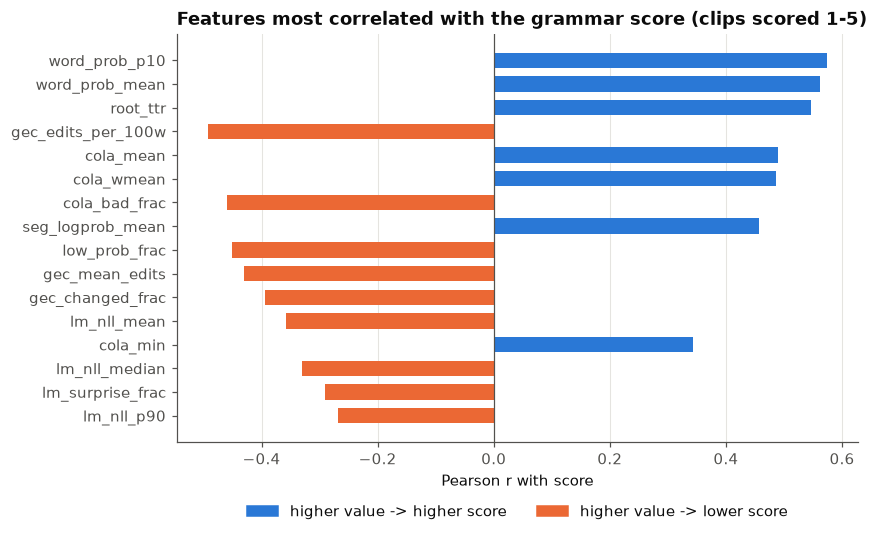

In [13]:
# How strongly does each hand-crafted feature relate to the score? (Pearson r on the training clips)
feat_df = meta[["key", "label"]].merge(acoustic, on="key").merge(text_features, on="key")
feat_df = feat_df[feat_df.label > 0]          # exclude the score-0 batch so the chart shows real grammar/fluency signal
corr = feat_df.drop(columns=["key", "label"] + LENGTH_DEPENDENT).corrwith(feat_df["label"]).dropna()   # only features the models use
top = corr.reindex(corr.abs().sort_values(ascending=False).index).head(16)[::-1]

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top.index, top.values, color=[BLUE if v > 0 else ORANGE for v in top.values], height=0.65)
ax.axvline(0, color=MUTED, lw=0.8)
ax.set(title="Features most correlated with the grammar score (clips scored 1-5)", xlabel="Pearson r with score")
ax.grid(axis="y", visible=False)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=BLUE, label="higher value -> higher score"), Patch(color=ORANGE, label="higher value -> lower score")], loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2)
plt.tight_layout(); plt.show()

The features match what you would expect. Clips that need fewer grammar corrections, have more grammatical sentences, are recognised more clearly by Whisper, and use a wider vocabulary get higher scores. No single feature is enough on its own, so the model combines all of them.

### 3.3 DeBERTa fine-tuned on the transcript
This is the one model we train directly on this task. It reads the whole transcript and predicts the score.

In [14]:
# ----- code that produced features/deberta_preds.csv (from src/05_finetune_deberta.py) ------------------------
import math, random
from transformers import AutoModel, get_cosine_schedule_with_warmup

DEBERTA_MODEL = "microsoft/deberta-v3-base"

MAX_LEN = 384

class TextRegressor(nn.Module):
    def __init__(self, init_bias: float):
        super().__init__()
        self.backbone = AutoModel.from_pretrained(DEBERTA_MODEL, hidden_dropout_prob=0.0, attention_probs_dropout_prob=0.0)
        # newer transformers keep the checkpoint's fp16 dtype; AMP needs fp32 master weights
        self.backbone.float()
        self.backbone.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})
        for p in self.backbone.embeddings.parameters():
            p.requires_grad = False
        self.head = nn.Linear(self.backbone.config.hidden_size, 1)
        nn.init.normal_(self.head.weight, std=0.02)
        nn.init.constant_(self.head.bias, init_bias)  # start at the mean label -> stable first steps

    def forward(self, input_ids, attention_mask):
        h = self.backbone(input_ids=input_ids, attention_mask=attention_mask).last_hidden_state
        m = attention_mask.unsqueeze(-1).to(h.dtype)
        pooled = (h * m).sum(1) / m.sum(1).clamp(min=1.0)  # mean pooling over real tokens
        return self.head(pooled).squeeze(-1)

def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

def make_batch(tok, enc, idx, device):
    batch = tok.pad({"input_ids": [enc["input_ids"][j] for j in idx],
                     "attention_mask": [enc["attention_mask"][j] for j in idx]}, return_tensors="pt")
    return batch["input_ids"].to(device), batch["attention_mask"].to(device)

@torch.inference_mode()
def predict(model, tok, enc, idx, device, batch_size=32):
    model.eval()
    order = sorted(idx, key=lambda j: len(enc["input_ids"][j]))  # length-sorted -> little padding
    preds = {}
    for i in range(0, len(order), batch_size):
        chunk = order[i : i + batch_size]
        ids, mask = make_batch(tok, enc, chunk, device)
        with torch.autocast(device.type, dtype=torch.float16, enabled=device.type == "cuda"):
            out = model(ids, mask).float().cpu().numpy()
        preds.update(zip(chunk, out))
    return np.array([preds[j] for j in idx])


def deberta_finetune(epochs=5, batch_size=8, lr=3e-5):

    device = get_device()
    use_amp = device.type == "cuda"
    meta = load_meta()
    transcripts = load_transcripts()
    texts = [transcripts[k]["text"] for k in meta["key"]]
    tok = AutoTokenizer.from_pretrained(DEBERTA_MODEL)
    enc = tok(texts, truncation=True, max_length=MAX_LEN)

    train_idx_all = np.where(meta["split"] == "train")[0]
    test_idx = np.where(meta["split"] == "test")[0]
    y = meta["label"].to_numpy()
    folds = meta["fold"].to_numpy()

    oof = np.full(len(meta), np.nan)
    test_pred = np.zeros(len(test_idx))
    insample = np.zeros(len(train_idx_all))

    for fold in range(N_FOLDS):
        seed_everything(SEED + fold)
        tr_idx = train_idx_all[folds[train_idx_all] != fold]
        va_idx = train_idx_all[folds[train_idx_all] == fold]

        model = TextRegressor(float(y[tr_idx].mean())).to(device)
        opt = torch.optim.AdamW(
            [{"params": [p for p in model.backbone.parameters() if p.requires_grad], "lr": lr},
             {"params": model.head.parameters(), "lr": 1e-3}],
            weight_decay=0.01,
        )
        steps = epochs * math.ceil(len(tr_idx) / batch_size)
        sched = get_cosine_schedule_with_warmup(opt, int(0.1 * steps), steps)
        scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
        rng = np.random.default_rng(SEED + fold)

        for epoch in range(epochs):
            model.train()
            perm = rng.permutation(tr_idx)
            losses = []
            for i in range(0, len(perm), batch_size):
                b = perm[i : i + batch_size]
                ids, mask = make_batch(tok, enc, b, device)
                target = torch.tensor(y[b], dtype=torch.float32, device=device)
                with torch.autocast(device.type, dtype=torch.float16, enabled=use_amp):
                    pred = model(ids, mask)
                loss = F.mse_loss(pred.float(), target)
                opt.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.unscale_(opt)
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                scaler.step(opt)
                scaler.update()
                sched.step()
                losses.append(loss.item())
            va_pred = predict(model, tok, enc, va_idx, device)
            va_rmse = np.sqrt(np.mean((va_pred - y[va_idx]) ** 2))
            print(f"fold {fold} epoch {epoch + 1}/{epochs}  train_mse {np.mean(losses):.3f}  "
                  f"val_rmse {va_rmse:.4f}")

        # fixed number of epochs (no best-epoch picking) keeps the OOF estimate honest
        oof[va_idx] = va_pred
        test_pred += predict(model, tok, enc, test_idx, device) / N_FOLDS
        insample += predict(model, tok, enc, train_idx_all, device) / N_FOLDS
        del model, opt
        torch.cuda.empty_cache()

    cv = np.sqrt(np.mean((oof[train_idx_all] - y[train_idx_all]) ** 2))
    print(f"DeBERTa OOF RMSE: {cv:.4f}")

    out = pd.DataFrame({"key": meta["key"], "deberta": oof, "deberta_insample": np.nan})
    out.loc[test_idx, "deberta"] = test_pred
    out.loc[train_idx_all, "deberta_insample"] = insample
    out.to_csv(FEAT_DIR / "deberta_preds.csv", index=False)
    print("saved deberta_preds.csv")


if RUN_HEAVY:
    deberta_finetune()
deb = pd.read_csv(FEAT_DIR / "deberta_preds.csv").set_index("key").reindex(meta["key"])
print(f"DeBERTa out-of-fold RMSE: {rmse(deb['deberta'].to_numpy()[is_tr_all], y_all):.4f}   (text alone, no audio)")

DeBERTa out-of-fold RMSE: 0.7853   (text alone, no audio)


## 4. Modelling and ensemble

We train six models on different inputs, then combine them.

<table>
<tr><td>Model</td><td>Input</td></tr>
<tr><td>tab_lgbm</td><td>hand-crafted audio and text features</td></tr>
<tr><td>tab_ridge</td><td>same features</td></tr>
<tr><td>wavlm_ridge</td><td>WavLM audio embedding</td></tr>
<tr><td>wavlm_svr</td><td>same embedding</td></tr>
<tr><td>cola_svr</td><td>transcript embedding from the CoLA model</td></tr>
<tr><td>deberta</td><td>the transcript, fine-tuned on the score</td></tr>
</table>

A simple linear model (the stacker) learns how much weight each of the six models gets, and the final scores are clipped to the 0 to 5 range. All results use 5-fold cross-validation, so every score is predicted by models that never saw that clip.

In [15]:
def run_ensemble(drop_zero=False, layer_rmse=None):
    """Train all base models, stack them, return predictions + metrics. drop_zero=True excludes the score-0 batch."""
    is_te = (meta["split"] == "test").to_numpy()
    is_tr = ~is_te
    if drop_zero:
        is_tr &= (meta["label"] > 0).to_numpy()
    tr, te = meta[is_tr].reset_index(drop=True), meta[is_te].reset_index(drop=True)
    y, folds = tr["label"].to_numpy(), tr["fold"].to_numpy()
    cv = CV(y, folds)

    def aligned(name):
        return pd.read_csv(FEAT_DIR / name).set_index("key").reindex(meta["key"])

    # tabular features; totals that scale with clip length are dropped (test clips are shorter)
    tab = pd.concat([acoustic.set_index("key").reindex(meta["key"]), aligned("text_features.csv")], axis=1)
    tab = tab.drop(columns=[c for c in LENGTH_DEPENDENT if c in tab.columns]).replace([np.inf, -np.inf], np.nan)
    tab_cols, X_tab = tab.columns.tolist(), tab.to_numpy(dtype=np.float64)

    res = {}                                                        # name -> (OOF, test, in-sample) predictions
    oof, test_p, ins, lgbm_full = cv.run(lgbm(), X_tab[is_tr], X_tab[is_te]); res["tab_lgbm"] = (oof, test_p, ins)
    oof, test_p, ins, _ = cv.run(ridge(), X_tab[is_tr], X_tab[is_te]); res["tab_ridge"] = (oof, test_p, ins)

    # WavLM: choose the layer by CV, average it with its neighbours
    if layer_rmse is None:
        layer_rmse = [rmse(cv.oof(ridge(), wavlm[is_tr, L]), y) for L in range(wavlm.shape[1])]
    best = int(np.argmin(layer_rmse))
    layers = [L for L in (best - 1, best, best + 1) if 0 <= L < wavlm.shape[1]]
    X_wav = wavlm[:, layers].mean(axis=1)
    oof, test_p, ins, _ = cv.run(ridge(), X_wav[is_tr], X_wav[is_te]); res["wavlm_ridge"] = (oof, test_p, ins)
    oof, test_p, ins, _ = cv.run(svr(pick_svr_c(cv, X_wav[is_tr])), X_wav[is_tr], X_wav[is_te]); res["wavlm_svr"] = (oof, test_p, ins)

    # CoLA-RoBERTa transcript embedding
    oof, test_p, ins, _ = cv.run(svr(pick_svr_c(cv, cola_emb[is_tr])), cola_emb[is_tr], cola_emb[is_te]); res["cola_svr"] = (oof, test_p, ins)

    # fine-tuned DeBERTa (predictions cached from section 3.3)
    d = pd.read_csv(FEAT_DIR / "deberta_preds.csv").set_index("key").reindex(meta["key"])
    res["deberta"] = (d["deberta"].to_numpy()[is_tr], d["deberta"].to_numpy()[is_te], d["deberta_insample"].to_numpy()[is_tr])

    # stacking
    names = list(res)
    P_oof, P_test, P_ins = (np.column_stack([res[n][i] for n in names]) for i in range(3))
    stacker = LinearRegression(positive=True)
    stack_oof = np.clip(cv.oof(stacker, P_oof), 0, 5)               # nested CV of the stacker itself
    stacker.fit(P_oof, y)
    final_test, final_ins = np.clip(stacker.predict(P_test), 0, 5), np.clip(stacker.predict(P_ins), 0, 5)

    nz = y > 0
    rows = [{"model": n, "cv_rmse": rmse(res[n][0], y), "cv_pearson": pearson(res[n][0], y), "stack_weight": float(w)}
            for n, w in zip(names, stacker.coef_)]
    rows.append({"model": "ENSEMBLE", "cv_rmse": rmse(stack_oof, y), "cv_pearson": pearson(stack_oof, y), "stack_weight": np.nan})
    return dict(y=y, folds=folds, tr=tr, te=te, names=names, P_oof=P_oof, P_test=P_test, stack_oof=stack_oof,
                final_test=final_test, final_ins=final_ins, stacker=stacker, table=pd.DataFrame(rows),
                layers=layers, layer_rmse=layer_rmse, lgbm_full=lgbm_full, tab_cols=tab_cols, cv=cv,
                metrics=dict(train_rmse=rmse(final_ins, y), train_pearson=pearson(final_ins, y),
                             cv_rmse=rmse(stack_oof, y), cv_pearson=pearson(stack_oof, y),
                             cv_rmse_nonzero=rmse(stack_oof[nz], y[nz]), baseline_rmse=rmse(np.full(len(y), y.mean()), y),
                             cv_mae=float(np.mean(np.abs(stack_oof - y))),
                             cv_r2=1 - float(np.sum((stack_oof - y) ** 2) / np.sum((y - y.mean()) ** 2))))


t0 = time.time()
main_run = run_ensemble(drop_zero=False, layer_rmse=layer_rmse_all)
print(f"ensemble trained in {time.time() - t0:.0f}s; WavLM layers used: {main_run['layers']}")
display(main_run["table"].round(4).set_index("model").fillna(""))

ensemble trained in 9s; WavLM layers used: [20, 21, 22]


,cv_rmse,cv_pearson,stack_weight
model,,,
tab_lgbm,0.6198,0.8658,0.1844
tab_ridge,0.7035,0.8230,0.0271
wavlm_ridge,0.5505,0.8958,0.1273
wavlm_svr,0.5227,0.9072,0.618
cola_svr,0.8312,0.7415,0.0998
deberta,0.7853,0.7757,0.0716
ENSEMBLE,0.4919,0.9180,


In [16]:
m = main_run["metrics"]
metrics_table = pd.DataFrame({
    "RMSE": [m["baseline_rmse"], m["train_rmse"], m["cv_rmse"]],
    "Pearson r": [np.nan, m["train_pearson"], m["cv_pearson"]],
}, index=["baseline: always predict the mean", "TRAINING data (models fitted on all 769 clips, predicting them)", "5-fold cross-validation (unseen clips)"])
display(metrics_table.round(4))
print(f"TRAINING RMSE = {m['train_rmse']:.4f}      CV RMSE = {m['cv_rmse']:.4f}      CV Pearson = {m['cv_pearson']:.4f}")
print(f"CV MAE = {m['cv_mae']:.3f} score points      CV R^2 = {m['cv_r2']:.3f}")

rep = json.loads((OUT_DIR / "cv_report.json").read_text())
print("matches the numbers stored by the script run (src/06):", abs(rep["cv_rmse"] - m["cv_rmse"]) < 1e-3 and abs(rep["train_rmse_insample"] - m["train_rmse"]) < 1e-3)

,RMSE,Pearson r
baseline: always predict the mean,1.2382,NaN
"TRAINING data (models fitted on all 769 clips, predicting them)",0.1124,0.9959
5-fold cross-validation (unseen clips),0.4919,0.9180


TRAINING RMSE = 0.1124      CV RMSE = 0.4919      CV Pearson = 0.9180
CV MAE = 0.367 score points      CV R^2 = 0.842
matches the numbers stored by the script run (src/06): True


the training RMSE (0.11) is low because the models are tested on the same clips they learned from. The cross-validated RMSE (0.49) is the honest estimate, because each clip is predicted by models that never saw it. The gap between them is normal overfitting on a small dataset, and the cross-validated number is the one that predicts the test score.

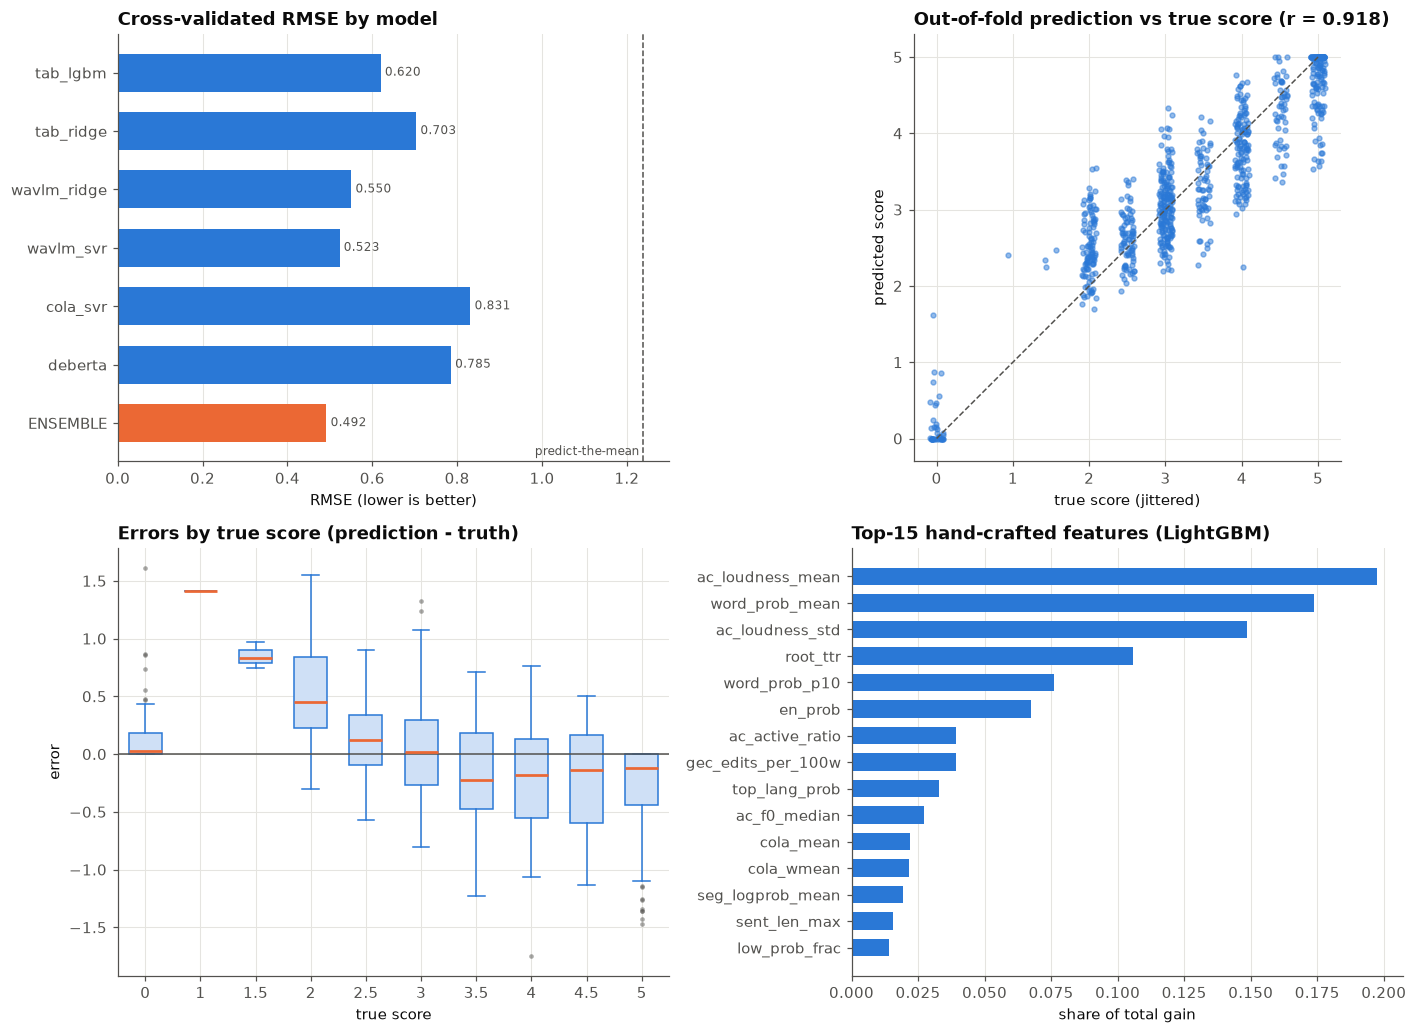

In [17]:
y, oof = main_run["y"], main_run["stack_oof"]
table = main_run["table"]
fig, axes = plt.subplots(2, 2, figsize=(13, 9.5))

# (a) model comparison
ax = axes[0, 0]
colors = [ORANGE if n == "ENSEMBLE" else BLUE for n in table["model"]]
ax.barh(table["model"], table["cv_rmse"], color=colors, height=0.65)
for i, v in enumerate(table["cv_rmse"]):
    ax.text(v + 0.01, i, f"{v:.3f}", va="center", fontsize=8, color=MUTED)
ax.axvline(1.238, color=MUTED, ls="--", lw=1); ax.text(1.23, 6.55, "predict-the-mean", ha="right", fontsize=8, color=MUTED)
ax.invert_yaxis(); ax.grid(axis="y", visible=False)
ax.set(title="Cross-validated RMSE by model", xlabel="RMSE (lower is better)", xlim=(0, 1.3))

# (b) predicted vs actual
ax = axes[0, 1]
jit = np.random.default_rng(0).uniform(-0.09, 0.09, len(y))
ax.scatter(y + jit, oof, s=10, color=BLUE, alpha=0.5)
ax.plot([0, 5], [0, 5], color=MUTED, lw=1, ls="--")
ax.set(title=f"Out-of-fold prediction vs true score (r = {pearson(oof, y):.3f})", xlabel="true score (jittered)", ylabel="predicted score",
       xlim=(-0.3, 5.3), ylim=(-0.3, 5.3)); ax.set_aspect("equal")

# (c) residuals by true score
ax = axes[1, 0]
levels = np.sort(np.unique(y))
bp = ax.boxplot([oof[y == v] - v for v in levels], patch_artist=True, widths=0.6, showfliers=True, flierprops=dict(marker="o", ms=3, mfc=MUTED, mec="none", alpha=0.5))
for box in bp["boxes"]:
    box.set(facecolor="#cfe0f6", edgecolor=BLUE)
for med in bp["medians"]:
    med.set(color=ORANGE, lw=1.8)
for w in bp["whiskers"] + bp["caps"]:
    w.set(color=BLUE)
ax.axhline(0, color=MUTED, lw=1)
ax.set_xticks(range(1, len(levels) + 1), [f"{v:g}" for v in levels])
ax.set(title="Errors by true score (prediction - truth)", xlabel="true score", ylabel="error")

# (d) LightGBM feature importance
ax = axes[1, 1]
imp = pd.Series(main_run["lgbm_full"].booster_.feature_importance("gain"), index=main_run["tab_cols"]).nlargest(15)[::-1]
ax.barh(imp.index, imp.values / imp.values.sum(), color=BLUE, height=0.65)
ax.set(title="Top-15 hand-crafted features (LightGBM)", xlabel="share of total gain"); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

Interpretation
* The ensemble beats every single model. The audio model (wavlm_svr) is the strongest on its own and gets the most weight.
* The predictions follow the diagonal. Errors are larger for very low and very high scores, where there are fewer examples.
* The model pulls predictions towards the middle: low scores are predicted slightly too high, and high scores slightly too low.

### Ensemble ablation
We rebuild the ensemble using only some of the models, to see how much each part contributes.

,CV RMSE,CV Pearson
models used,,
audio embedding only (WavLM ridge + SVR),0.5126,0.9106
text / hand-crafted only (no WavLM),0.5944,0.8773
everything except DeBERTa,0.4919,0.9180
everything except the CoLA embedding,0.4927,0.9177
full ensemble,0.4919,0.9180


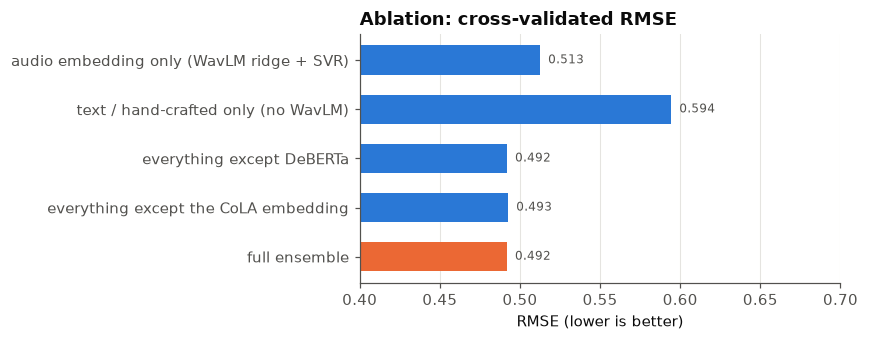

In [18]:
def stack_cv(res, subset):
    idx = [res["names"].index(n) for n in subset]
    p = np.clip(res["cv"].oof(LinearRegression(positive=True), res["P_oof"][:, idx]), 0, 5)
    return rmse(p, res["y"]), pearson(p, res["y"])

audio_models = ["wavlm_ridge", "wavlm_svr"]
text_models = ["tab_lgbm", "tab_ridge", "cola_svr", "deberta"]     # tabular features mix audio prosody and transcript stats
groups = {
    "audio embedding only (WavLM ridge + SVR)": audio_models,
    "text / hand-crafted only (no WavLM)": text_models,
    "everything except DeBERTa": [n for n in main_run["names"] if n != "deberta"],
    "everything except the CoLA embedding": [n for n in main_run["names"] if n != "cola_svr"],
    "full ensemble": main_run["names"],
}
abl = pd.DataFrame([{"models used": k, "CV RMSE": stack_cv(main_run, v)[0], "CV Pearson": stack_cv(main_run, v)[1]} for k, v in groups.items()])
display(abl.round(4).set_index("models used"))

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.barh(abl["models used"], abl["CV RMSE"], color=[ORANGE if k == "full ensemble" else BLUE for k in abl["models used"]], height=0.6)
for i, v in enumerate(abl["CV RMSE"]):
    ax.text(v + 0.005, i, f"{v:.3f}", va="center", fontsize=8, color=MUTED)
ax.invert_yaxis(); ax.grid(axis="y", visible=False); ax.set(title="Ablation: cross-validated RMSE", xlabel="RMSE (lower is better)", xlim=(0.4, 0.7))
plt.tight_layout(); plt.show()

The audio embeddings do most of the work on their own (RMSE 0.513). Adding the transcript-based models improves the ensemble to 0.492, so both sound and content help. Removing DeBERTa or the CoLA embedding changes almost nothing.

## 5. Ablation: the 37 label-0 clips
Do the label-0 clips help or hurt? We train the ensemble once with them and once without, then compare both on the same clips (those with a label above 0), so the numbers are comparable.

In [20]:
dz_run = run_ensemble(drop_zero=True)
cmp = pd.DataFrame({
    "training clips": [len(main_run["y"]), len(dz_run["y"])],
    "CV RMSE on clips with score > 0": [main_run["metrics"]["cv_rmse_nonzero"], dz_run["metrics"]["cv_rmse_nonzero"]],
    "training RMSE": [main_run["metrics"]["train_rmse"], dz_run["metrics"]["train_rmse"]],
}, index=["all labels (submitted)", "score-0 batch dropped"])
display(cmp.round(4))

# how do the two test predictions differ?
diff = main_run["final_test"] - dz_run["final_test"]
print(f"test predictions: correlation {np.corrcoef(main_run['final_test'], dz_run['final_test'])[0, 1]:.4f}, RMS difference {np.sqrt(np.mean(diff**2)):.3f}")
z = main_run["y"] == 0
print(f"the all-labels model recognises the score-0 clips: mean out-of-fold prediction on them = {main_run['stack_oof'][z].mean():.2f}")

,training clips,CV RMSE on clips with score > 0,training RMSE
all labels (submitted),769,0.4963,0.1124
score-0 batch dropped,732,0.4948,0.1342


test predictions: correlation 0.9942, RMS difference 0.089
the all-labels model recognises the score-0 clips: mean out-of-fold prediction on them = 0.20


Decision: the two versions are effectively tied (0.4963 against 0.4948, a difference that is just noise), and their test predictions are almost identical (correlation 0.994). We submit the version trained on all the labels, since it is the simpler choice and it can still give a low score to clips like the label-0 ones if the hidden test set contains any.

## 6. Final predictions and submission file

rows: 216 | columns: ['filename', 'label']
max |difference| to the file uploaded to Kaggle (outputs/submission.csv): 8.881784197001252e-16


,filename,label
0,audio_128.wav,2.884821
1,audio_156.wav,4.194894
2,audio_19.wav,4.747206
3,audio_108.wav,1.916376
4,audio_206.wav,2.198878


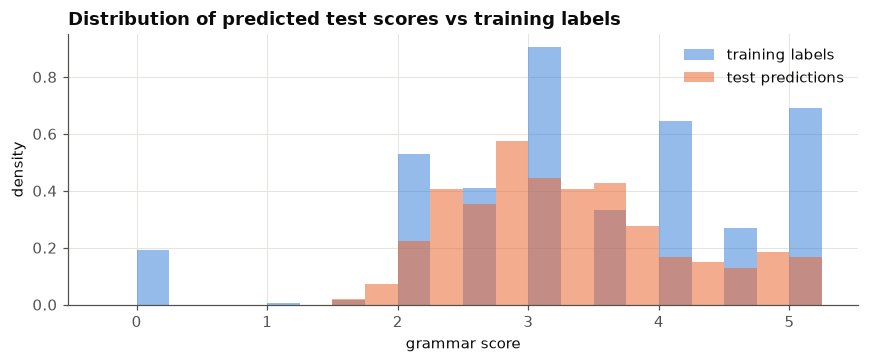

In [21]:
sub = pd.DataFrame({"filename": main_run["te"]["filename"], "label": main_run["final_test"]})
test_csv = pd.read_csv(DATA_DIR / "test.csv")

assert len(sub) == 216 and set(sub["filename"]) == set(test_csv["filename"])      # one row per test clip, same names as test.csv
assert sub["label"].between(0, 5).all() and sub["label"].notna().all()            # valid scores in [0, 5]
sub.to_csv(OUT_DIR / "submission_notebook.csv", index=False)

uploaded = pd.read_csv(OUT_DIR / "submission.csv")
print(f"rows: {len(sub)} | columns: {list(sub.columns)}")
print("max |difference| to the file uploaded to Kaggle (outputs/submission.csv):", float(np.abs(uploaded.set_index("filename")["label"] - sub.set_index("filename")["label"]).max()))
display(sub.head())

fig, ax = plt.subplots(figsize=(8, 3.4))
edges = np.arange(-0.25, 5.5, 0.25)
ax.hist(tr_meta["label"], bins=edges, density=True, color=BLUE, alpha=0.5, label="training labels")
ax.hist(sub["label"], bins=edges, density=True, color=ORANGE, alpha=0.55, label="test predictions")
ax.set(title="Distribution of predicted test scores vs training labels", xlabel="grammar score", ylabel="density"); ax.legend()
plt.tight_layout(); plt.show()

### Result
scored 0.3540 on the public leaderboard


That is better than the cross-validated RMSE of about 0.49.

## 7. Limitations and next steps
The dataset is small (769 clips) and the human scores are noisy, especially for low scores. The next steps would be fine-tuning the audio model and trying a larger language model on the transcripts.

## 8. For reproducing..

In [22]:
import importlib.metadata as md_
versions = {p: md_.version(p) for p in ["torch", "transformers", "faster-whisper", "scikit-learn", "lightgbm", "numpy", "pandas"]}
print("python", platform.python_version(), "|", ", ".join(f"{k} {v}" for k, v in versions.items()))
print("seed:", SEED, "| folds:", N_FOLDS, "| GPU used for the cached features: NVIDIA RTX 3050 Laptop (4 GB)")

python 3.13.7 | torch 2.11.0+cu128, transformers 5.17.0, faster-whisper 1.2.1, scikit-learn 1.9.1, lightgbm 4.7.0, numpy 2.5.3, pandas 3.0.6
seed: 42 | folds: 5 | GPU used for the cached features: NVIDIA RTX 3050 Laptop (4 GB)


To rerun everything from scratch: install the requirements, extract the dataset to data/, set RUN_HEAVY = True and run all cells (about 2 hours on a 4 GB GPU). The same steps are also available as scripts in src/.